# GSE173682: Ovarian & Endometrial Cancer

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2026-01-16
> - Modified: 2026-01-16
---

> - Regner, Matthew J. et al. A multi-omic single-cell landscape of human gynecologic malignancies. Molecular Cell, Volume 81, Issue 23, 4924 - 4941.e10
> - [GSE173682](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE173682)
> - Organism: Homo sapiens
> - Cancer type: Ovarian and endometrial cancer
> - UNC Lineberger Cancer Center
> - 2021-12-02

---

# Experimental Design

> - scRNA-seq: 10x Genomics Chromium Single Cell 3’ GEM Kit v3
> - scATAC-seq: 10x Genomics Chromium Single Cell ATAC Library Kit v1
> - Illumina NextSeq 500
> - Cell Ranger v3.1.0
> - Cell Ranger ATAC v1.2.0
> - GRCh38

| Patient | Cancer type | Tumor site | Histology | Stage | Age | Race | Disease status |
| - | - | - | - | - | - | - | - |
| Patient 1 (3533EL) | Endometrial | Endometrium | Endometrioid | IA | 70 | AA | Primary endometrial cancer  |
| Patient 2 (3571DL) | Endometrial | Endometrium | Endometrioid | IA | 70 | CAU | Primary endometrial cancer |
| Patient 3 (36186L) | Endometrial | Endometrium | Endometrioid | IA | 70 | CAU | Primary endometrial cancer |
| Patient 4 (36639L) | Endometrial | Endometrium | Endometrioid | IA | 49 | CAU | Primary endometrial cancer |
| Patient 5 (366C5L) | Endometrial | Endometrium | Endometrioid | IA | 62 | CAU | Primary endometrial cancer |
| Patient 6 (37EACL) | Endometrial | Ovary | Serous | IIIA | 74 | CAU | Endometrial cancer ovary metastasis |
| Patient 7 (38FE7L) | Ovarian | Ovary | Endometrioid | IA | 76 | CAU | Primary ovary cancer |
| Patient 8 (3BAE2L) | Ovarian | Ovary | High-grade serous ovarian cancer (HGSOC) | IIB | 61 | CAU | Primary ovary cancer |
| Patient 9 (3E5CFL) | Ovarian | Ovary | High-grade serous ovarian cancer (HGSOC) | IIIC | 59 | AS | Primary ovary cancer |
| Patient 10 (3CCF1L) | Ovarian | Ovary | Carcinosarcoma | IVB | 69 | CAU | Primary ovary cancer |
| Patient 11 (3E4D1L) | Gastric | Ovary | Gastrointestinal stromal tumor (GIST) | IV | 59 | CAU | Gastric cancer ovary metastasis |

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/TumorBiology/Hs_OvarianAndEndometrialCancer_GSE173682"

In [3]:
dir.create(file.path(data_dir, "result"), 
           recursive = TRUE, showWarnings = FALSE)
# dir.create(file.path(data_dir, "visualization"), 
#            recursive = TRUE, showWarnings = FALSE)

In [4]:
samples <- file.path(data_dir, "matrix") |>
    list.files(full.names = FALSE, recursive = FALSE) %>%
    set_names(gsub("^GSM[0-9]+_", "", .)) %>%
    keep(names(.) %in% paste0("Patient", 1:5))

paste(names(samples), samples, sep = ": ") |> cat(sep = "\n")

Patient1: GSM5276933_Patient1
Patient2: GSM5276934_Patient2
Patient3: GSM5276935_Patient3
Patient4: GSM5276936_Patient4
Patient5: GSM5276937_Patient5


In [5]:
load_matrix_to_seurat <- function(
    data_dir, path, name = path) {
    
    file.path(data_dir, path) |> 
        Read10X() |>
        CreateSeuratObject(project = name)
}

In [6]:
scrna_list <- mapply(
    FUN = load_matrix_to_seurat,
    path = samples,
    name = names(samples),
    MoreArgs = list(data_dir = file.path(data_dir, "matrix")), 
    SIMPLIFY = FALSE)

In [7]:
scrna_list[[1]]

An object of class Seurat 
33538 features across 5697 samples within 1 assay 
Active assay: RNA (33538 features, 0 variable features)
 1 layer present: counts

# 2. Quality Control

In [8]:
cell_stats <- function(obj_list) {
    cells_per_object <- vapply(
        obj_list, function(x) length(Cells(x)), 
        FUN.VALUE = integer(1))
    total_cells <- sum(cells_per_object)
    
    c(cells_per_object, Total = total_cells)
}

In [9]:
scrna_list |> cell_stats() |> print()

Patient1 Patient2 Patient3 Patient4 Patient5    Total 
    5697     7963     6054     8110     8403    36227 


## 1). Filtering Genes

In [10]:
filter_low_detected_genes <- function(
    obj_list, min_cells = 3) {

    genes_list <- lapply(obj_list, function(obj){
        mat <- LayerData(obj, layer = "counts")
        gene_detect <- rowSums(mat > 0)
        names(gene_detect[gene_detect >= min_cells])
    })
    names(genes_list) <- names(obj_list)
    
    keep_genes <- Reduce(union, genes_list)
    
    message("Genes after filtering in each layer:")
    print(lengths(genes_list))
    message("Final intersected gene count: ", length(keep_genes))

    return(keep_genes)
}

In [11]:
keep_genes <- filter_low_detected_genes(
    scrna_list, min_cells = 3)

Genes after filtering in each layer:



Patient1 Patient2 Patient3 Patient4 Patient5 
   21977    23233    23986    21453    23802 


Final intersected gene count: 26147



In [12]:
scrna_list <- lapply(
    scrna_list, function(obj) 
        subset(obj, features = keep_genes))

## 2). Calculate Metrics

In [13]:
calculate_qc_metrics <- function(
    obj, species = c("human", "mouse")) {
    
    species <- match.arg(species)
    
    # Mitochondrial genes
    mt_pattern <- "(?i)^MT-"
    obj <- PercentageFeatureSet(
        obj, pattern = mt_pattern, col.name = "percent.mt")
    
    # Ribosomal genes
    rp_pattern <- "(?i)^(MRP|RP[LS])"
    obj <- PercentageFeatureSet(
        obj, pattern = rp_pattern, col.name = "percent.rp")
    
    # Hemoglobin genes
    hb_pattern <- switch(
        species,
        human = "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)",
        mouse = "^(Hb[ab]-|Hbq1[ab])"
    )
    obj <- PercentageFeatureSet(
        obj, pattern = hb_pattern, col.name = "percent.hb")
    
    return(obj)
}

In [14]:
scrna_list <- lapply(
    scrna_list, calculate_qc_metrics, species = "human")

## 3). Visualizate Metrics

In [15]:
source("R/run_seurat_pipeline.R")

In [16]:
sc.temp <- merge(x = scrna_list[[1]], y = scrna_list[-1],
                 add.cell.ids = names(scrna_list)) |>
    run_seurat_pipeline(ndim = 20)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


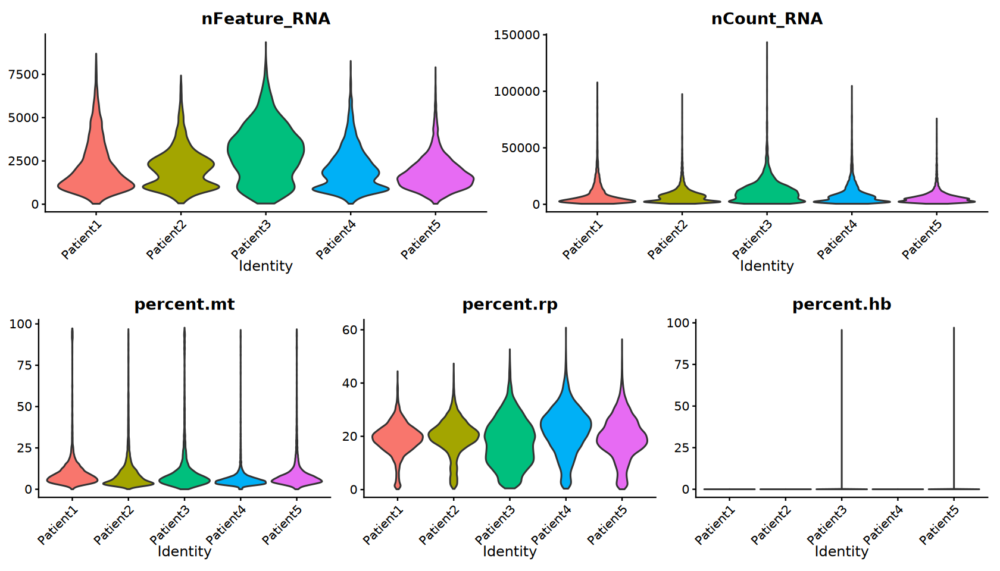

In [17]:
# Visualize QC metrics as a violin plot
p1 <- VlnPlot(
    sc.temp, layer = "counts", group.by = "orig.ident", 
    features = c("nFeature_RNA", "nCount_RNA"), 
    pt.size = 0, ncol = 2) & NoLegend()
p2 <- VlnPlot(
    sc.temp, layer = "counts", group.by = "orig.ident", 
    features = c("percent.mt", "percent.rp", "percent.hb"), 
    pt.size = 0, ncol = 3) & NoLegend()

options(repr.plot.width = 14, repr.plot.height = 8)
plot_grid(p1, p2, ncol = 1)

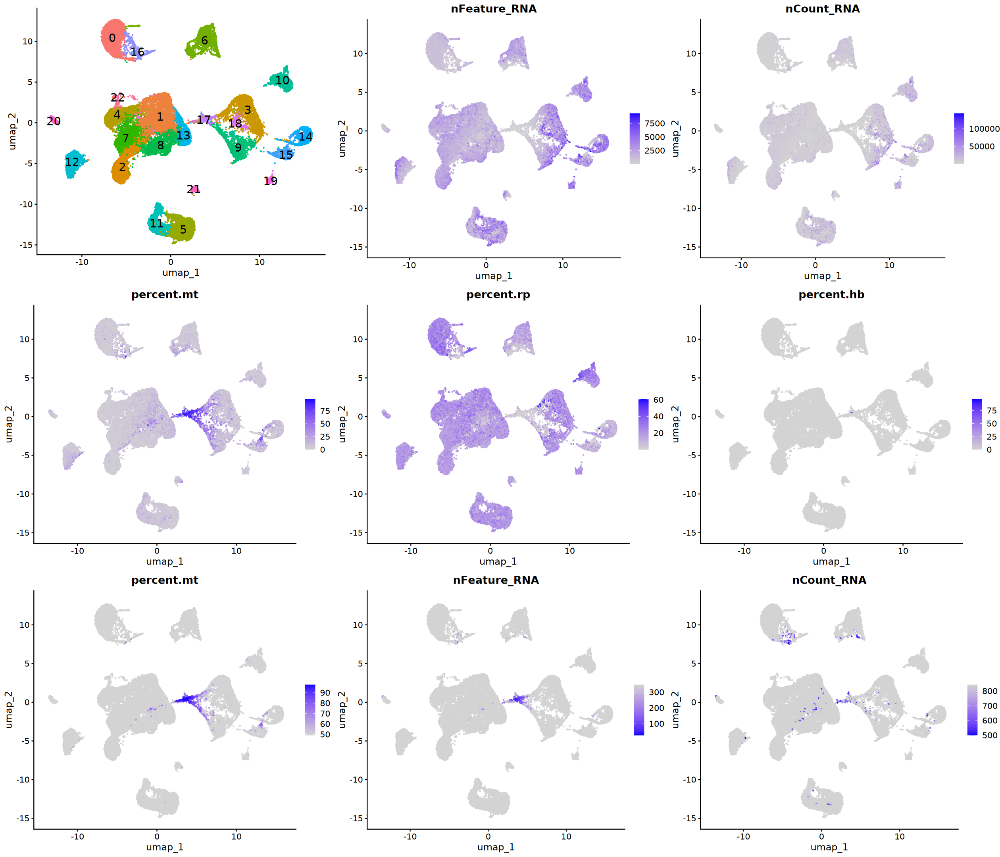

In [18]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", features = "percent.mt",
    min.cutoff = "q98", order = TRUE, combine = FALSE)
p4 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q2", cols = c("blue", "lightgrey"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [19]:
source("R/calculate_mad_threshold.R")

In [20]:
cat(sprintf("Counts: Lower: %d\n", calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 2, sides = "lower")))

cat(sprintf("Features: Lower: %d\n", calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 2, sides = "lower")))

cat(sprintf("Mitochondrial: Upper: %d\n", calculate_mad_threshold(
    sc.temp$percent.mt, nmads = 2, sides = "upper")))

Counts: Lower: 837
Features: Lower: 477
Mitochondrial: Upper: 23


## 4). Filtering Low-quality Cells

In [21]:
scrna_list <- lapply(
    scrna_list, subset, 
    subset = nFeature_RNA > 500 & 
        percent.mt < 20)

scrna_list |> cell_stats() |> print()

Patient1 Patient2 Patient3 Patient4 Patient5    Total 
    5208     7098     5323     7692     7659    32980 


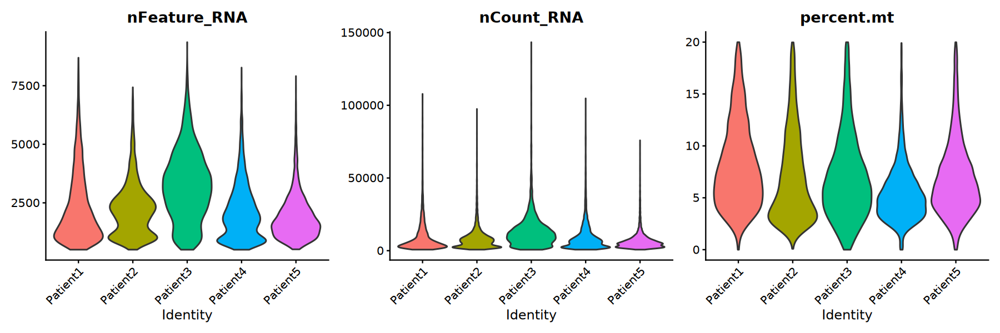

In [22]:
options(repr.plot.width = 15, repr.plot.height = 5)
merge(x = scrna_list[[1]], y = scrna_list[-1],
      add.cell.ids = names(scrna_list)) |>
    VlnPlot(layer = "counts", group.by = "orig.ident", 
            features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), 
            pt.size = 0, ncol = 3) & NoLegend()

## 5). Doublet Detection

### a). [DoubletFinder](https://github.com/chris-mcginnis-ucsf/DoubletFinder)

In [23]:
source("R/run_DoubletFinder.R")

In [24]:
scrna_list <- lapply(
    scrna_list, run_DoubletFinder, ndim = 20, 
    clusters = "seurat_clusters", 
    multiplet.rate = 0.008, seed = 123)

[1] "Creating 1736 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.11, nExp_adj = 191



[1] "Creating 2366 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.26, nExp_adj = 351



[1] "Creating 1774 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.14, nExp_adj = 198



[1] "Creating 2564 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.21, nExp_adj = 421



[1] "Creating 2553 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.22, nExp_adj = 426



In [25]:
sapply(scrna_list, function(x) table(x$DoubletFinder.class))

,Patient1,Patient2,Patient3,Patient4,Patient5
Singlet,5017,6747,5125,7271,7233
Doublet,191,351,198,421,426


### b). [scDblFinder](https://github.com/plger/scDblFinder)

In [26]:
suppressPackageStartupMessages(library(scDblFinder))

In [27]:
run_scDblFinder <- function(
    obj, clusters = NULL, ndim = 10, seed = NULL) {
    
    if (!is.null(seed)) set.seed(seed)
    
    sce <- run_seurat_pipeline(obj, ndim = ndim) |>
        as.SingleCellExperiment()
    
    if (is.null(clusters)) {
        sce <- scDblFinder(sce, verbose = FALSE)
    } else {
        sce <- scDblFinder(
            sce, clusters = clusters, verbose = FALSE)
    }

    obj$scDblFinder.score <- colData(sce)$scDblFinder.score
    obj$scDblFinder.class <- colData(sce)$scDblFinder.class

    return(obj)
}

In [28]:
scrna_list <- lapply(
    scrna_list, run_scDblFinder, ndim = 20,
    clusters = "seurat_clusters", seed = 123)

In [29]:
sapply(scrna_list, function(x) table(x$scDblFinder.class))

,Patient1,Patient2,Patient3,Patient4,Patient5
singlet,4784,6490,4899,6982,6931
doublet,424,608,424,710,728


### Filtering Doublets

In [30]:
sc.comb <- merge(
    x = scrna_list[[1]], y = scrna_list[-1],
    add.cell.ids = names(scrna_list), 
    project = "EndometrialCancer")
sc.comb

An object of class Seurat 
26147 features across 32980 samples within 1 assay 
Active assay: RNA (26147 features, 0 variable features)
 5 layers present: counts.Patient1, counts.Patient2, counts.Patient3, counts.Patient4, counts.Patient5

In [31]:
sc.temp <- run_seurat_pipeline(sc.comb, ndim = 20)

In [32]:
sc.temp$scDblFinder.class <- sc.temp$scDblFinder.class |>
    factor(levels = c("singlet", "doublet"))
sc.temp$DoubletFinder.class <- sc.temp$DoubletFinder.class |>
    factor(levels = c("Singlet", "Doublet"))

In [33]:
table(scDblFinder = sc.temp$scDblFinder.class, 
      DoubletFinder = sc.temp$DoubletFinder.class)

           DoubletFinder
scDblFinder Singlet Doublet
    singlet   28964    1122
    doublet    2429     465

In [34]:
sc.temp$isDoublet <- apply(
    sc.temp@meta.data[, c(
        "scDblFinder.class", "DoubletFinder.class")],
    1, function(x) paste(x, collapse = "_")
    ) |> as.factor()

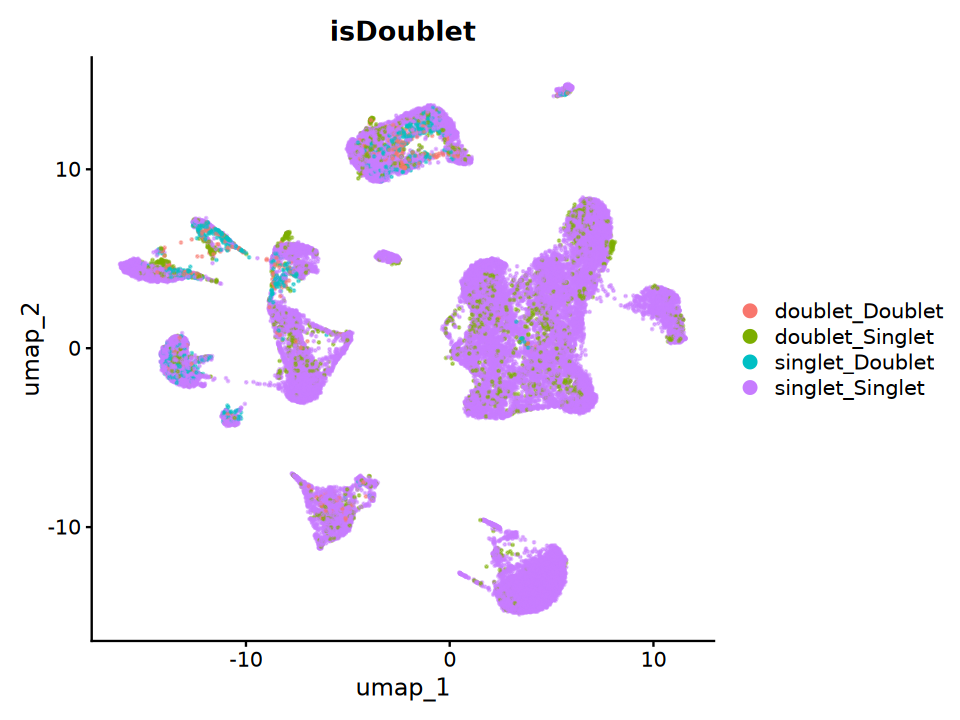

In [35]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(sc.temp, reduction = "umap", 
        group.by = "isDoublet", 
        pt.size = 0.1, alpha = 0.5)

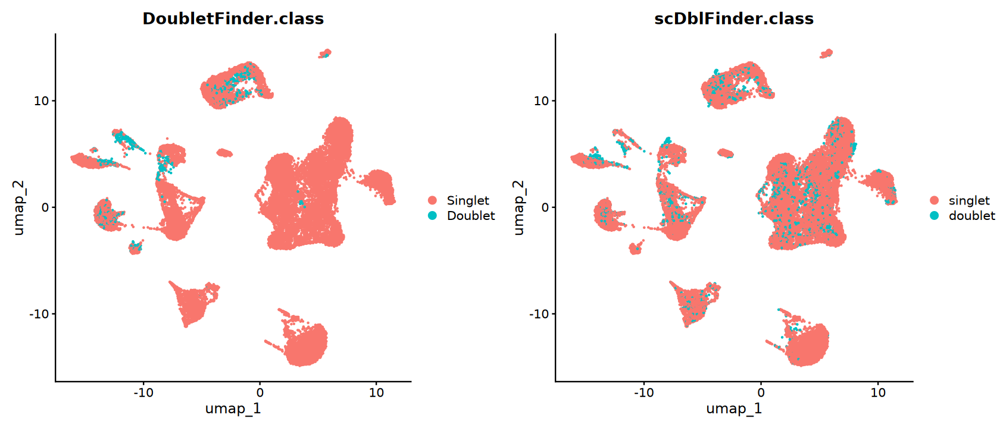

In [36]:
p1 <- DimPlot(
    subset(sc.temp, subset = scDblFinder.class == "singlet"),
    reduction = "umap", group.by = "DoubletFinder.class")
p2 <- DimPlot(
    subset(sc.temp, subset = DoubletFinder.class == "Singlet"), 
    reduction = "umap", group.by = "scDblFinder.class")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [37]:
sc.temp <- subset(
    sc.temp,
    subset = scDblFinder.class == "singlet" | 
        DoubletFinder.class == "Singlet")
sc.temp

An object of class Seurat 
26147 features across 32515 samples within 1 assay 
Active assay: RNA (26147 features, 2000 variable features)
 11 layers present: counts.Patient1, counts.Patient2, counts.Patient3, counts.Patient4, counts.Patient5, data.Patient1, data.Patient2, data.Patient3, data.Patient4, data.Patient5, scale.data
 3 dimensional reductions calculated: pca, umap, tsne

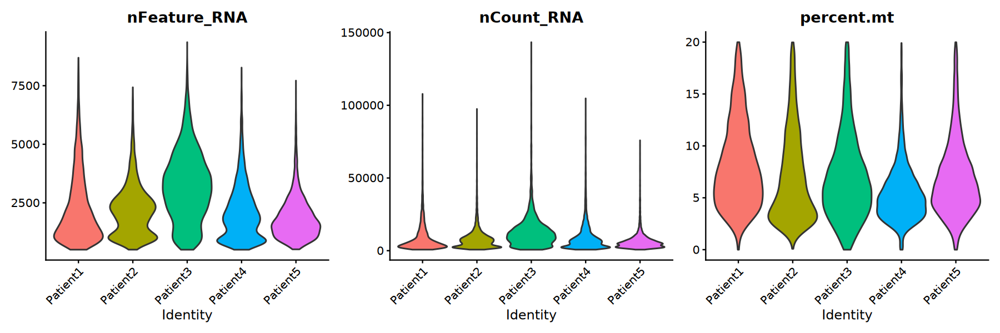

In [38]:
options(repr.plot.width = 15, repr.plot.height = 5)
VlnPlot(sc.temp, layer = "counts", group.by = "orig.ident", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), 
        pt.size = 0, ncol = 3) & NoLegend()

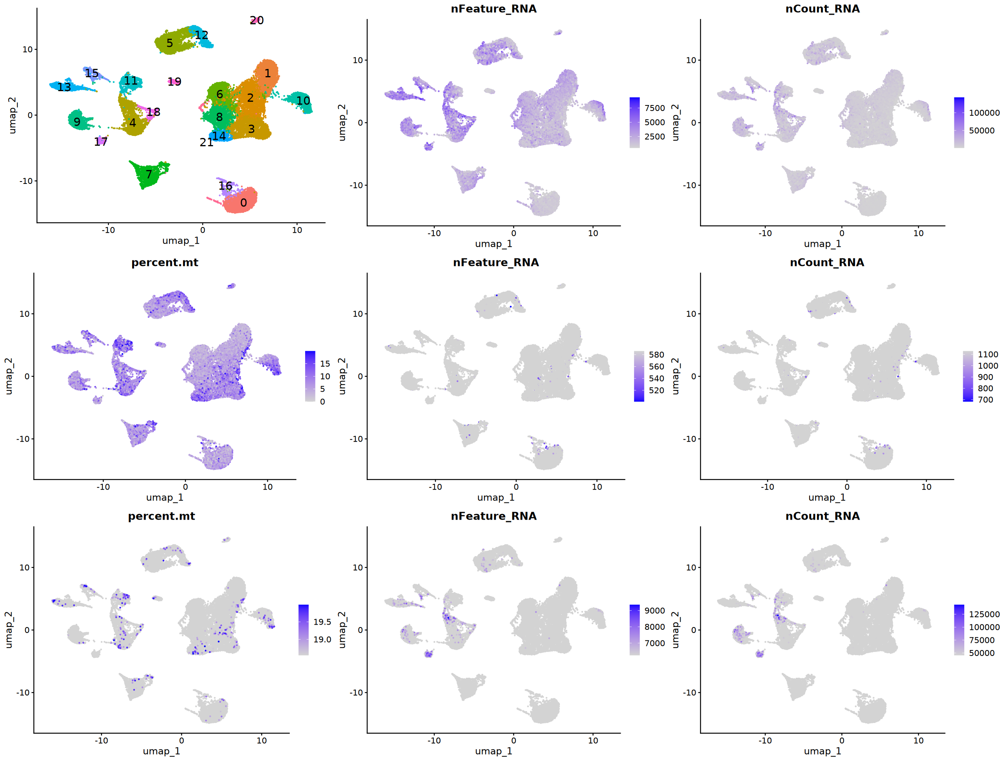

In [39]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))
p4 <- FeaturePlot(
    sc.temp, reduction = "umap",
    features = c("percent.mt", "nFeature_RNA", "nCount_RNA"),
    min.cutoff = "q99", order = TRUE, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3, byrow = TRUE)

In [40]:
summary(sc.temp@meta.data[, c("nFeature_RNA", "nCount_RNA", "percent.mt")])

  nFeature_RNA    nCount_RNA       percent.mt    
 Min.   : 501   Min.   :   683   Min.   : 0.000  
 1st Qu.:1239   1st Qu.:  3256   1st Qu.: 3.928  
 Median :1990   Median :  6428   Median : 5.903  
 Mean   :2254   Mean   :  9018   Mean   : 6.783  
 3rd Qu.:2901   3rd Qu.: 11169   3rd Qu.: 8.739  
 Max.   :9355   Max.   :143402   Max.   :19.988  

In [41]:
cat(sprintf("Counts: Upper: %d\n", calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 2, sides = "upper")))

cat(sprintf("Features: Upper: %d\n", calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 2, sides = "upper")))

Counts: Upper: 38982
Features: Upper: 6909


In [42]:
sc.comb <- sc.comb |> 
    subset(
        subset = scDblFinder.class == "singlet" | 
            DoubletFinder.class == "Singlet") |>
    subset(
        subset = nCount_RNA < 50000 & 
            percent.mt < 20 & percent.hb < 1)
sc.comb

An object of class Seurat 
26147 features across 32269 samples within 1 assay 
Active assay: RNA (26147 features, 0 variable features)
 5 layers present: counts.Patient1, counts.Patient2, counts.Patient3, counts.Patient4, counts.Patient5

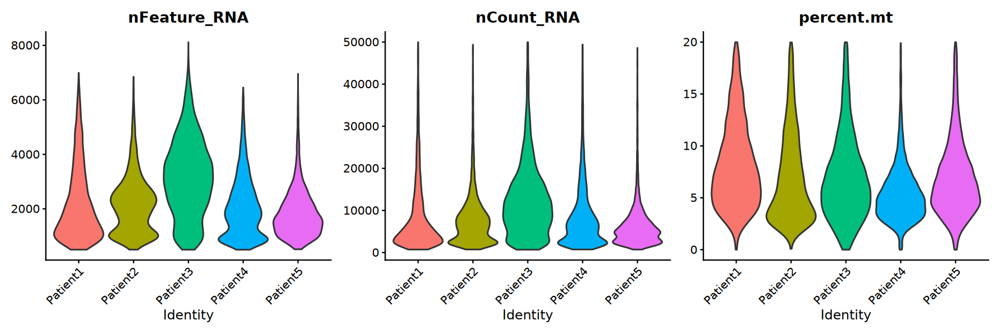

In [43]:
options(repr.plot.width = 15, repr.plot.height = 5)
VlnPlot(sc.comb, layer = "counts", group.by = "orig.ident", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), 
        pt.size = 0, ncol = 3) & NoLegend()

## 6). Evaluating Noise

### a). Cell cycle effect

In [44]:
calculate_cell_cycle_score <- function(
    obj, species = c("human", "mouse")) {

    species <- match.arg(species)

    cc_s <- switch(
        species,
        "human" = cc.genes$s.genes,
        "mouse" = stringr::str_to_title(cc.genes$s.genes),
        tolower(cc.genes$s.genes))
    
    cc_g2m <- switch(
        species,
        "human" = cc.genes$g2m.genes,
        "mouse" = stringr::str_to_title(cc.genes$g2m.genes),
        tolower(cc.genes$g2m.genes))
    
    obj <- NormalizeData(obj, verbose = FALSE) |>
        CellCycleScoring(s.features = cc_s, g2m.features = cc_g2m, 
                         set.ident = FALSE)

    return(obj)
}

In [45]:
sc.comb <- calculate_cell_cycle_score(sc.comb, species = "human")

Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in 

### b). Cell dissociation effect

In [46]:
dissociation_genes <- readLines(
    "~/data1/single_cell_dataset/reference_infomation/dissociation_genes.txt")

In [47]:
calculate_dissociation_score <- function(
    obj, species = c("human", "mouse")) {
    
    species <- match.arg(species)

    diss_genes <- switch(
        species,
        "human" = toupper(dissociation_genes),
        "mouse" = dissociation_genes,
        tolower(dissociation_genes)
    )
    
    obj <- NormalizeData(obj, verbose = FALSE) |>
        AddModuleScore(name = "Dissociation.Score", 
                       features = list(dissociationGenes = diss_genes))
    obj@meta.data <- obj@meta.data |> 
        dplyr::rename("Dis.Score" = "Dissociation.Score1")
    
    return(obj)
}

In [48]:
sc.comb <- calculate_dissociation_score(sc.comb, species = "human")

Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”


### c). Batch effect

In [49]:
sc.temp <- run_seurat_pipeline(sc.comb, ndim = 20)

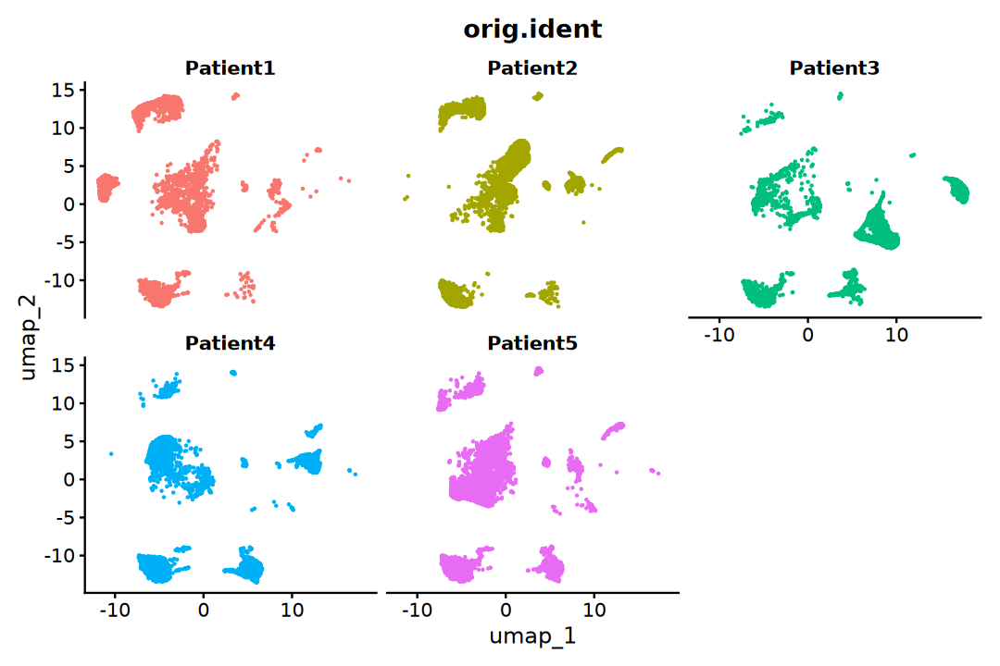

In [50]:
options(repr.plot.width = 9, repr.plot.height = 6)
DimPlot(sc.temp, reduction = "umap", group.by = "orig.ident", 
        split.by = "orig.ident", ncol = 3) & NoLegend()

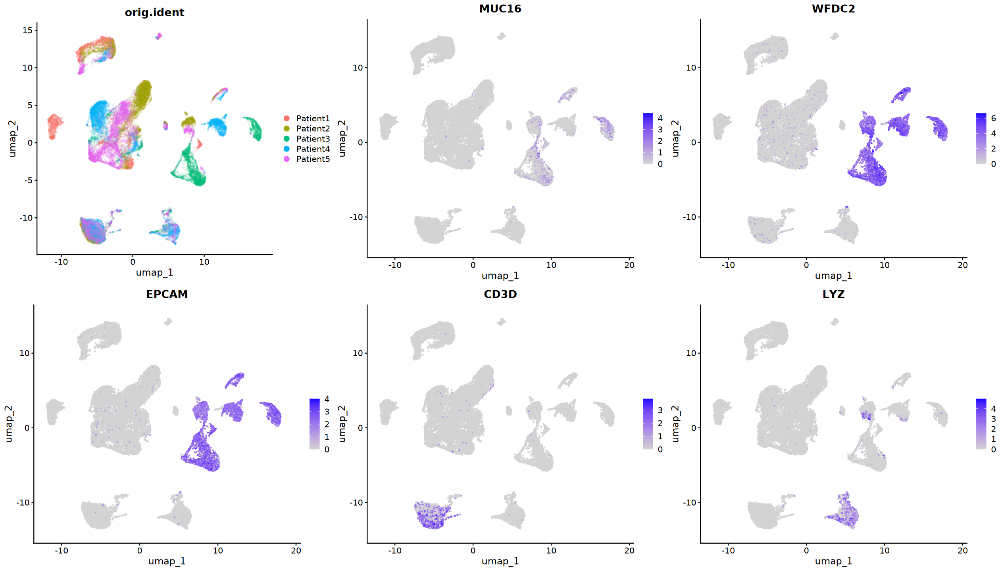

In [51]:
geneset <- c("MUC16", "WFDC2", "EPCAM", "CD3D", "LYZ")
p1 <- DimPlot(
    sc.temp, reduction = "umap", group.by = "orig.ident", 
    pt.size = 0.1, alpha = 0.1, label = FALSE)
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", features = geneset,
    combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

# 3. Initial Assessment

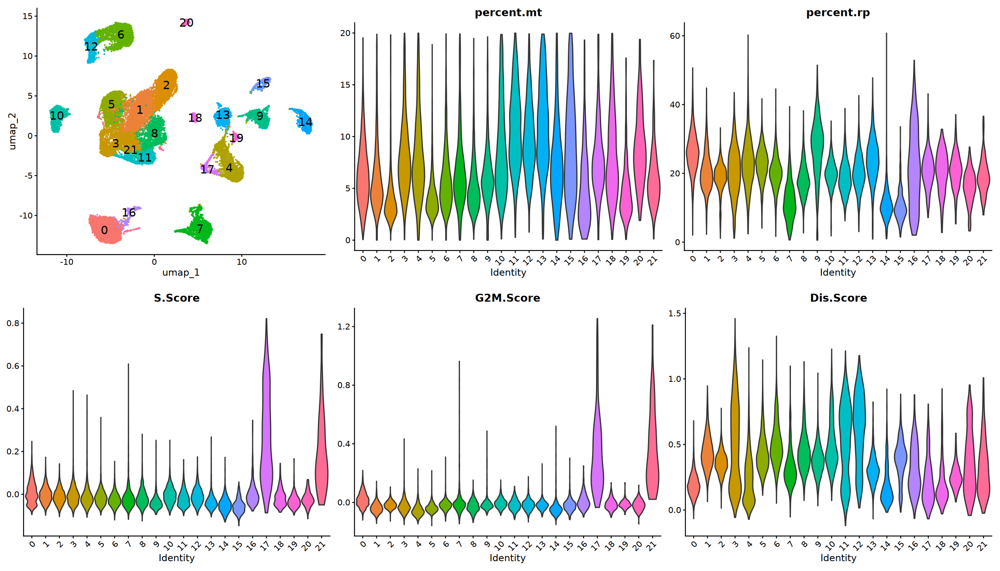

In [52]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- VlnPlot(
    sc.temp, features = c("percent.mt", "percent.rp"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    sc.temp, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

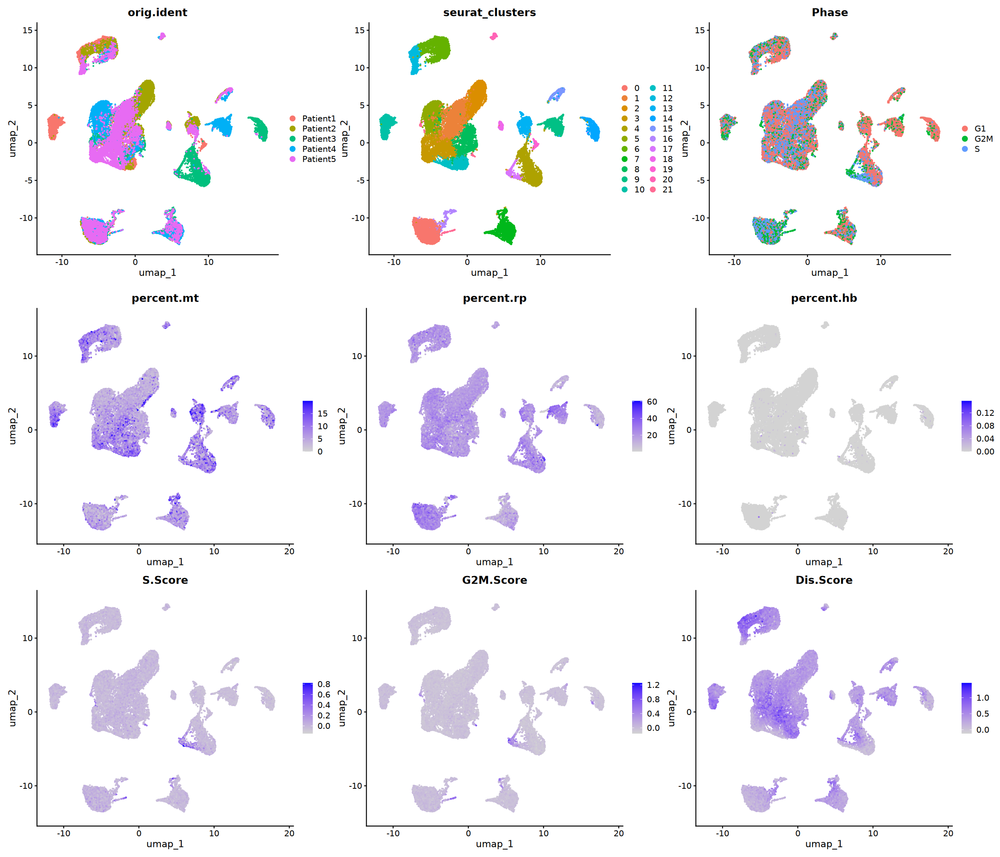

In [53]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", combine = FALSE,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2), ncol = 3)

# 4. Normalization

In [57]:
sc.comb <- NormalizeData(sc.comb, verbose = FALSE) |>
    FindVariableFeatures(nfeatures = 2000, verbose = FALSE) |>
    ScaleData(vars.to.regress = "percent.mt", verbose = FALSE)

# 5. Linear Dimensionality Reduction

In [58]:
sc.comb <- RunPCA(sc.comb, npcs = 50, verbose = FALSE)

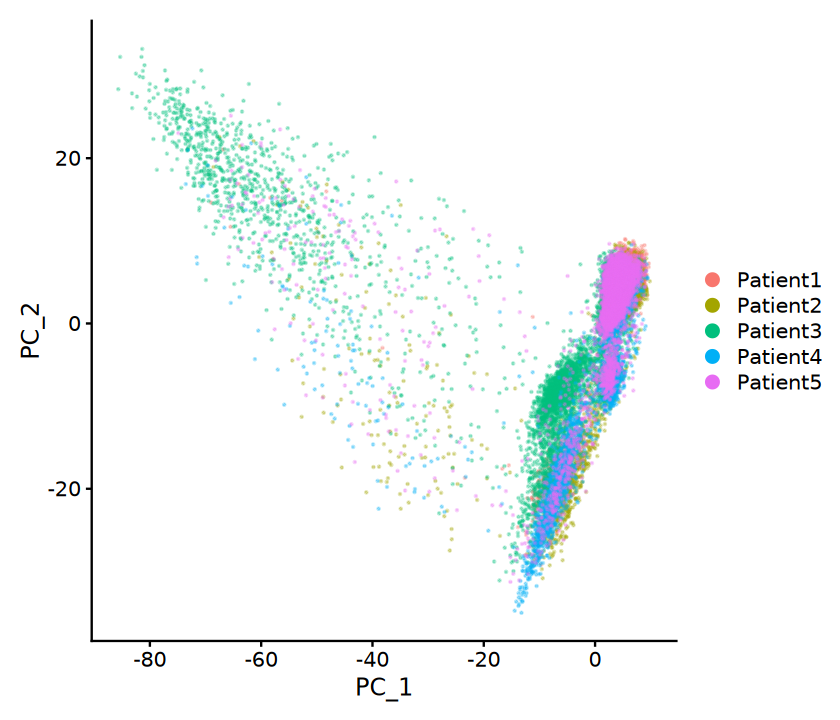

In [59]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(sc.comb, reduction = "pca", alpha = 0.3)

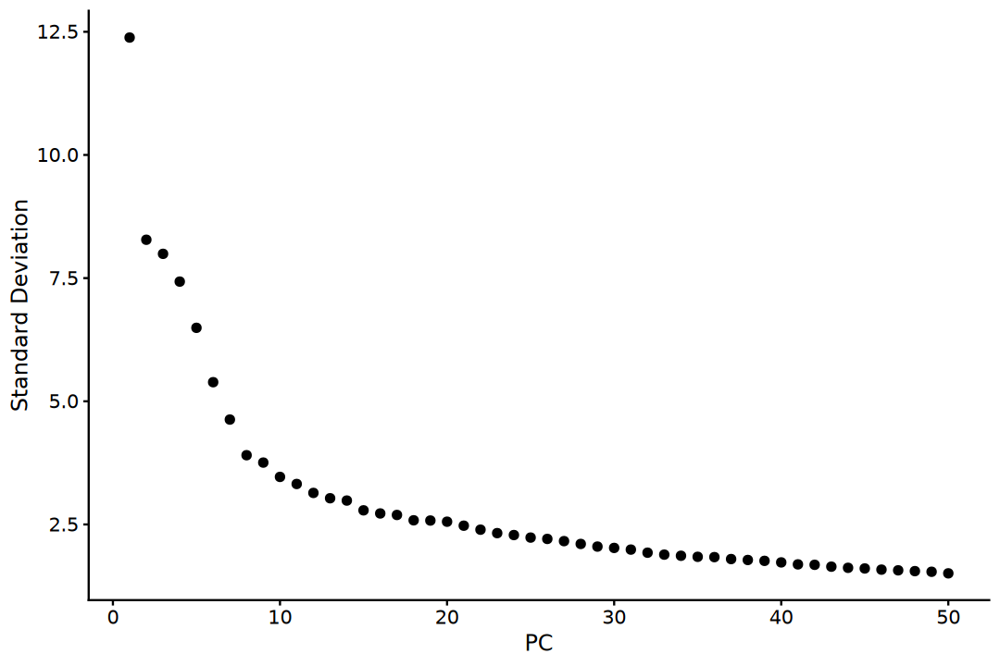

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(sc.comb, ndims = 50)

In [61]:
# Estimating PCA dimensionality
pca_var <- sc.comb@reductions$pca@stdev^2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 29


In [62]:
nPCs <- 30

# 6. Integration

In [63]:
sc.inte <- IntegrateLayers(
    sc.comb, method = CCAIntegration, orig.reduction = "pca", 
    new.reduction = "cca", verbose = FALSE)

In [64]:
suppressPackageStartupMessages(library(harmony))

In [65]:
sc.inte <- RunHarmony(sc.inte, "orig.ident", verbose = FALSE)

## Visualization

In [66]:
sc.inte

An object of class Seurat 
26147 features across 32269 samples within 1 assay 
Active assay: RNA (26147 features, 2000 variable features)
 11 layers present: counts.Patient1, counts.Patient2, counts.Patient3, counts.Patient4, counts.Patient5, data.Patient1, data.Patient2, data.Patient3, data.Patient4, data.Patient5, scale.data
 3 dimensional reductions calculated: pca, cca, harmony

In [67]:
plot_inte_res <- function(obj, dims = 10, reduction) {
    
    obj <- RunUMAP(
        obj, dims = 1:dims, reduction = reduction, 
        verbose = FALSE)
    obj <- RunTSNE(
        obj, dims = 1:dims, reduction = reduction, 
        verbose = FALSE)

    p1 <- DimPlot(
        obj, reduction = reduction, group.by = "orig.ident", 
        pt.size = 0.1, alpha = 0.1)
    p2 <- DimPlot(
        obj, reduction = "umap", group.by = "orig.ident", 
        pt.size = 0.1, alpha = 0.1)
    p3 <- DimPlot(
        obj, reduction = "tsne", group.by = "orig.ident", 
        pt.size = 0.1, alpha = 0.1)
    
    plot_grid(p1, p2, p3, ncol = 1)
}

In [68]:
methods <- c("pca", "cca", "harmony")

pg_list <- lapply(methods, function(redu) {
    plot_inte_res(sc.inte, nPCs, redu)
})

In [69]:
titles <- c("non-integrate", "CCA", "Harmony")

title_list <- lapply(titles, function(text) {
    ggdraw() + draw_label(
        text, angle = 0, fontface = 'bold', size = 20)
})

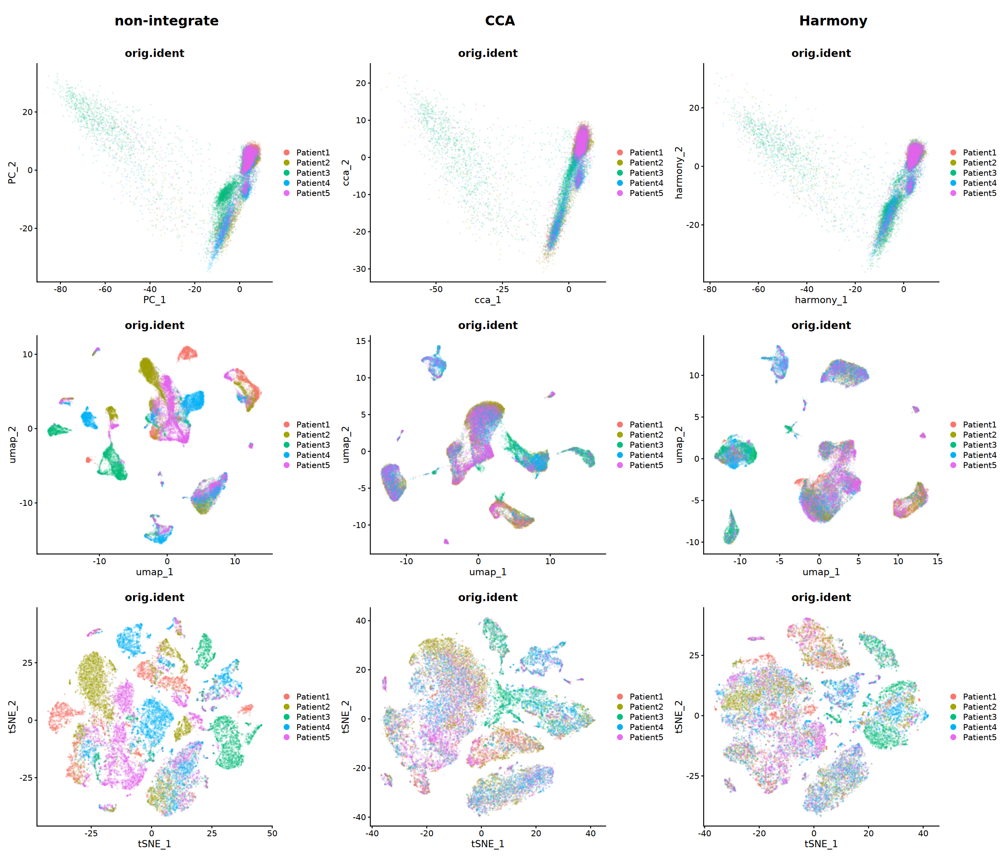

In [70]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(
    plot_grid(plotlist = title_list, ncol = 3), 
    plot_grid(plotlist = pg_list, ncol = 3), 
    ncol = 1, rel_heights = c(0.05, 1))

In [71]:
inte <- "harmony"

In [72]:
sc.inte <- JoinLayers(sc.inte)
sc.inte

An object of class Seurat 
26147 features across 32269 samples within 1 assay 
Active assay: RNA (26147 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 3 dimensional reductions calculated: pca, cca, harmony

# 7. Neighborhood Graph Construction

In [73]:
sc.inte <- FindNeighbors(
    sc.inte, k.param = 20, reduction = inte, 
    dims = 1:nPCs, verbose = FALSE)

# 8. Non-linear Dimensionality Reduction

In [74]:
sc.inte <- RunUMAP(
    sc.inte, dims = seq_len(nPCs), reduction = inte, 
    verbose = FALSE)

In [75]:
sc.inte <- RunTSNE(
    sc.inte, dims = seq_len(nPCs), reduction = inte,
    verbose = FALSE)

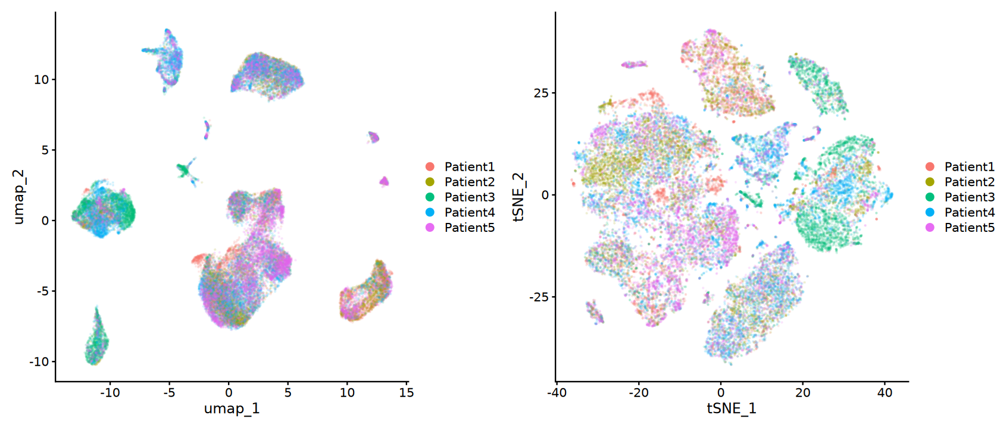

In [76]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", pt.size = 0.1, alpha = 0.1)
p2 <- DimPlot(
    sc.inte, reduction = "tsne", pt.size = 0.1, alpha = 0.1)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 9. Clustering

In [77]:
source("R/scan_clustering_resolution.R")

In [78]:
cluster_list <- scan_clustering_resolution(
    sc.inte, reduction = "pca", dims = nPCs,
    resolution = seq(0.1, 0.9, 0.1), assess = FALSE)

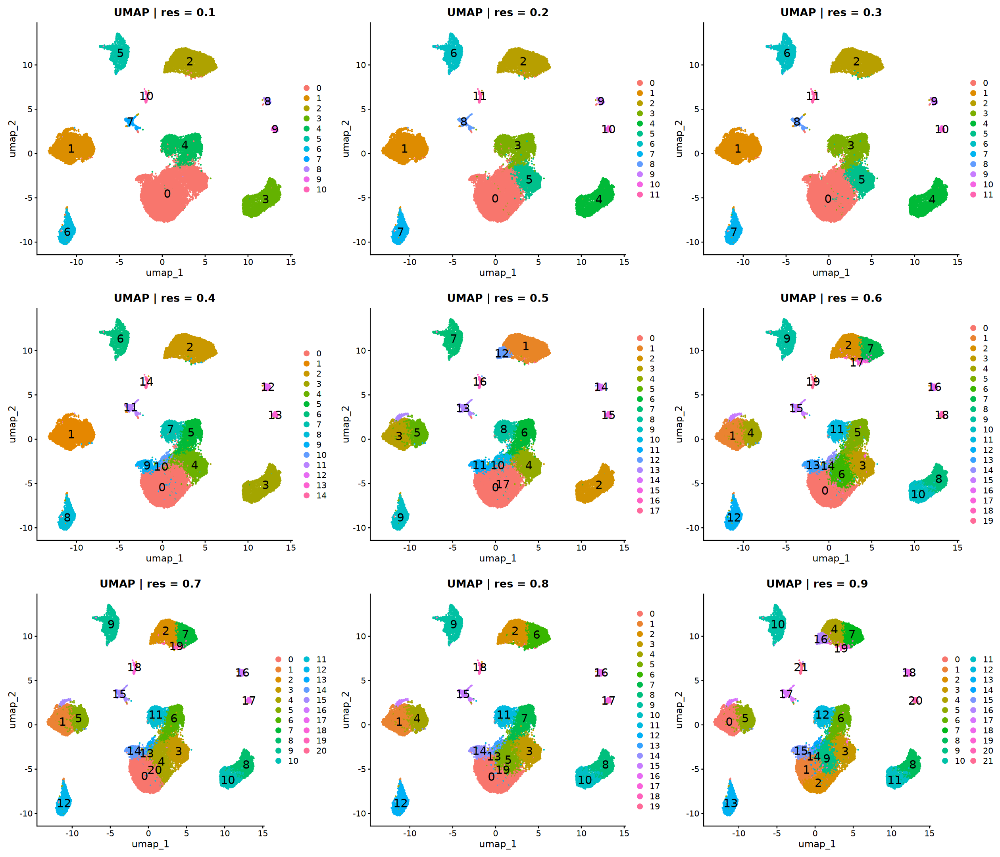

In [79]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$umap, ncol = 3)

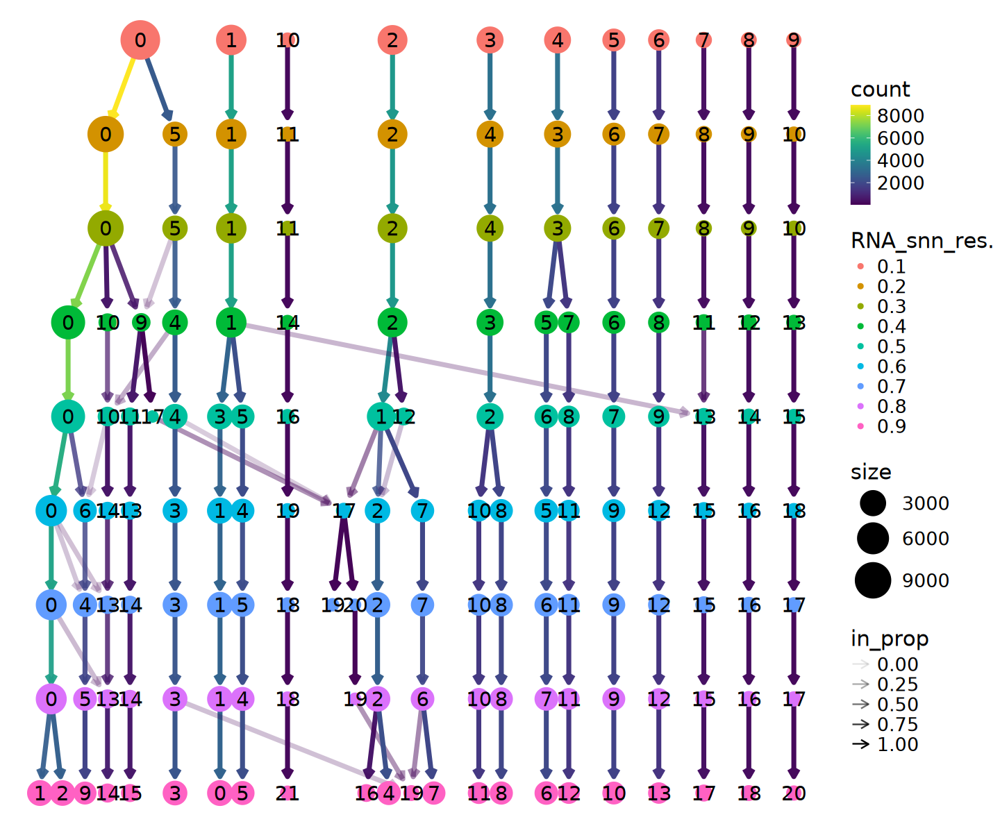

In [80]:
options(repr.plot.width = 12, repr.plot.height = 10)
cluster_list$clustree

In [81]:
sc.inte <- FindClusters(
    sc.inte, resolution = 0.1, verbose = FALSE)

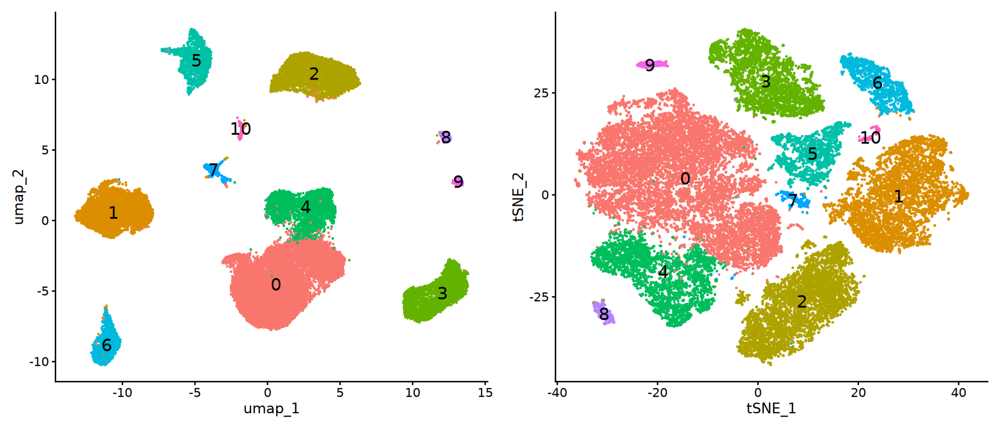

In [82]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", label = TRUE,
    label.size = 6) & NoLegend()
p2 <- DimPlot(
    sc.inte, reduction = "tsne", label = TRUE,
    label.size = 6) & NoLegend()

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

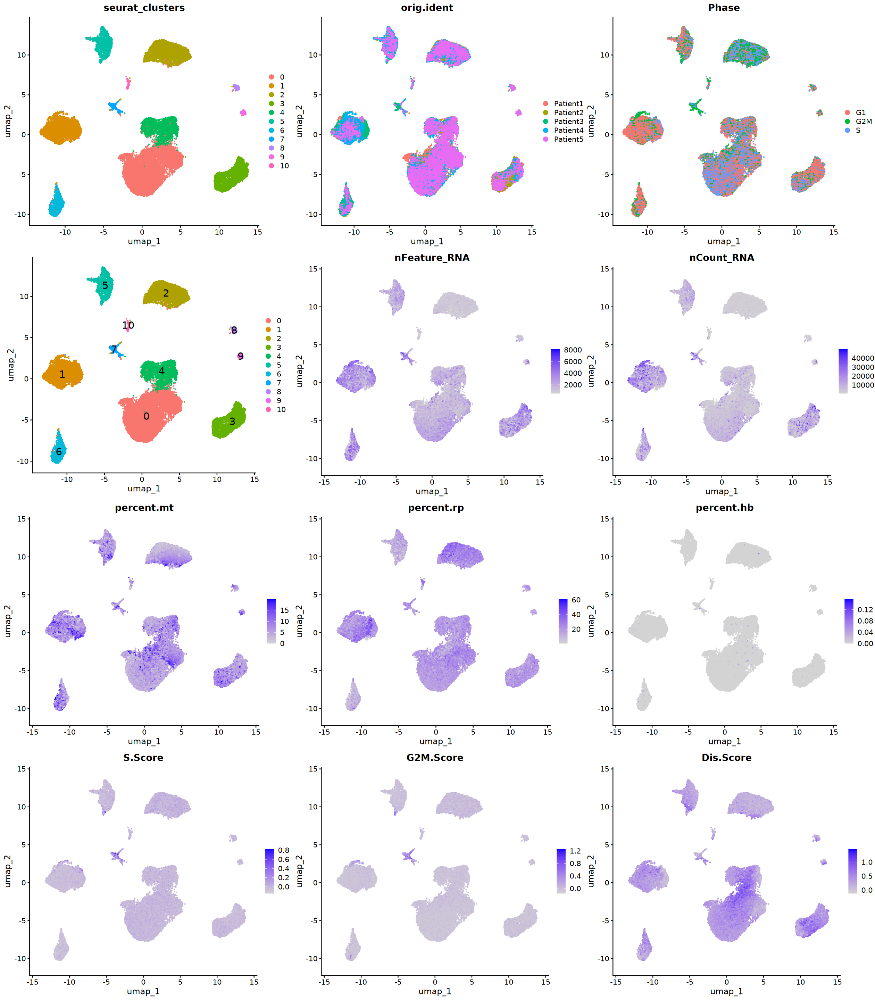

In [83]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", combine = FALSE,
    group.by = c("seurat_clusters", "orig.ident", "Phase"))
p2 <- DimPlot(
    sc.inte, reduction = "umap", label = TRUE,
    label.size = 6)
p3 <- FeaturePlot(
    sc.inte, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"))
p4 <- FeaturePlot(
    sc.inte, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

# 10. Cluster Biomarkers

In [84]:
sc.markers <- FindAllMarkers(
    sc.inte, logfc.threshold = log2(1.2), 
    min.pct = 0.25, only.pos = TRUE, 
    verbose = FALSE)

In [85]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [86]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,10
length(gene),214,1360,92,918,92,451,2944,2782,85,525,63


In [87]:
top10 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

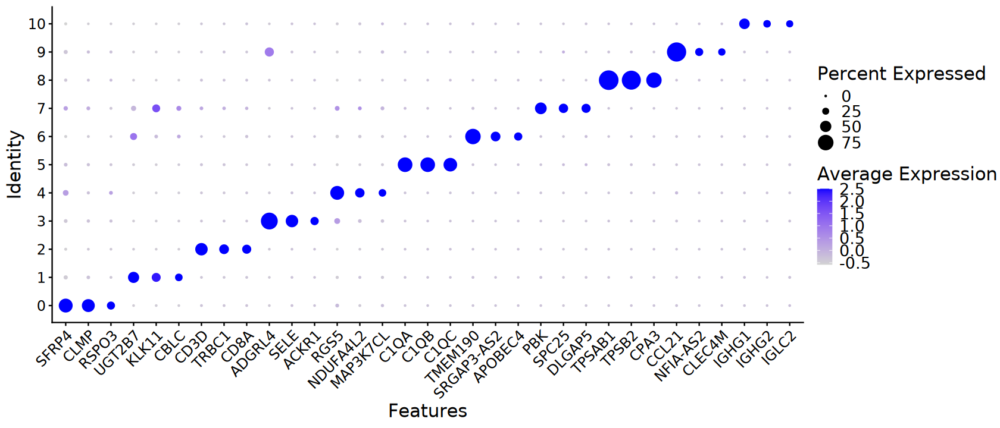

In [88]:
options(repr.plot.width = 14, repr.plot.height = 6)
DotPlot(sc.inte, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 14),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

# 11. Cell-type Annotation

## a). Automatic

In [89]:
suppressPackageStartupMessages(library(SingleR))
# suppressPackageStartupMessages(library(celldex))

In [90]:
ref_endometrium <- readRDS(
    "~/data1/single_cell_dataset/GSE111976/GSE111976_ct_endo_10x.rds")

In [91]:
ref_coldata <- read.csv(
    "~/data1/single_cell_dataset/GSE111976/GSE111976_summary_10x_day_donor_ctype.csv", 
    header = TRUE, row.names = 1)

In [92]:
ref_umap <- read.csv(
    "~/data1/single_cell_dataset/GSE111976/GSE111976_umap_endo_10x.csv", 
    header = TRUE, row.names = 1)

In [93]:
ref_endometrium <- SingleCellExperiment(
    list(counts = ref_endometrium), 
    colData = ref_coldata)

ref_endometrium <- scuttle::logNormCounts(ref_endometrium)
reducedDims(ref_endometrium)$UMAP <- as.matrix(ref_umap)

ref_endometrium

class: SingleCellExperiment 
dim: 33538 71032 
metadata(0):
assays(2): counts logcounts
rownames(33538): MIR1302-2HG FAM138A ... AC213203.1 FAM231C
rowData names(0):
colnames(71032): 14_AAACCCAAGTAATACG 14_AAACCCAGTCCTTAAG ...
  63_TTTGTTGTCATCTGTT 63_TTTGTTGTCGGATACT
colData names(5): day donor cell_type cell_name sizeFactor
reducedDimNames(1): UMAP
mainExpName: NULL
altExpNames(0):

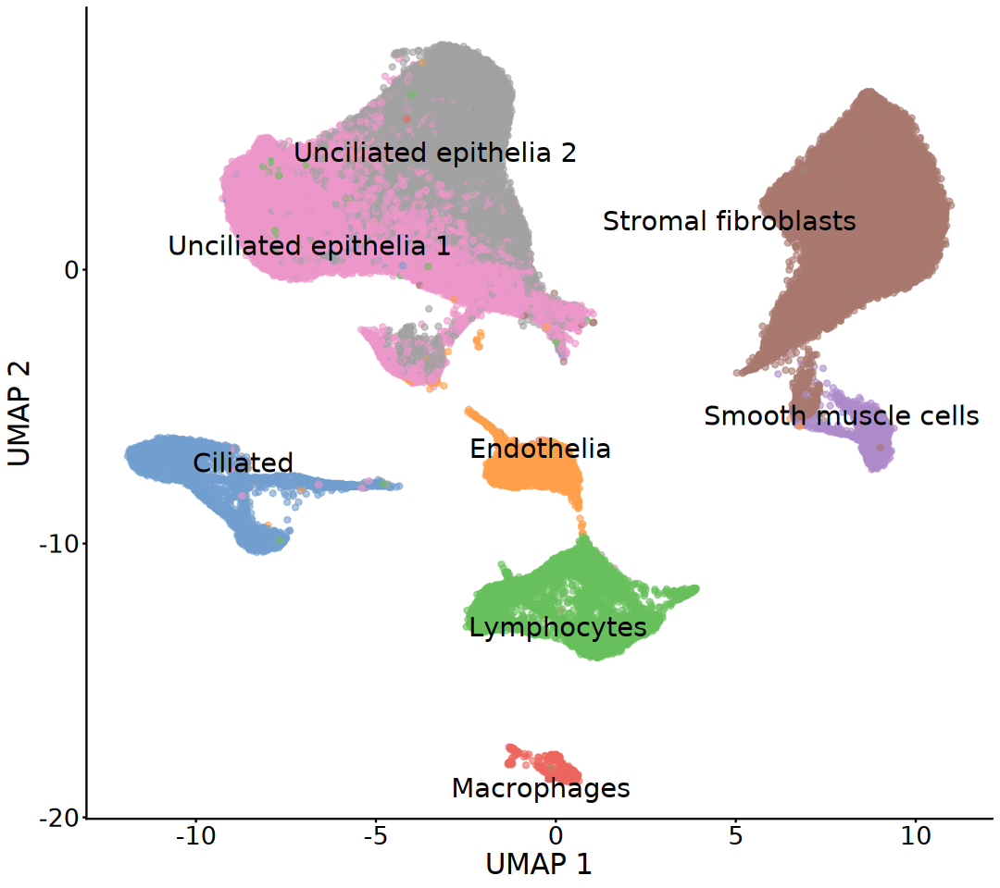

In [94]:
options(repr.plot.width = 9, repr.plot.height = 8)
scater::plotReducedDim(
    ref_endometrium, dimred = "UMAP", color_by = "cell_type",
    text_by="cell_type", text_size = 6) +
    theme(legend.position = "none", 
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16))

In [95]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    sc.inte, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_endometrium, 
            labels = ref_endometrium$cell_type, 
            clusters = sc.inte$seurat_clusters,
            de.method = "wilcox")

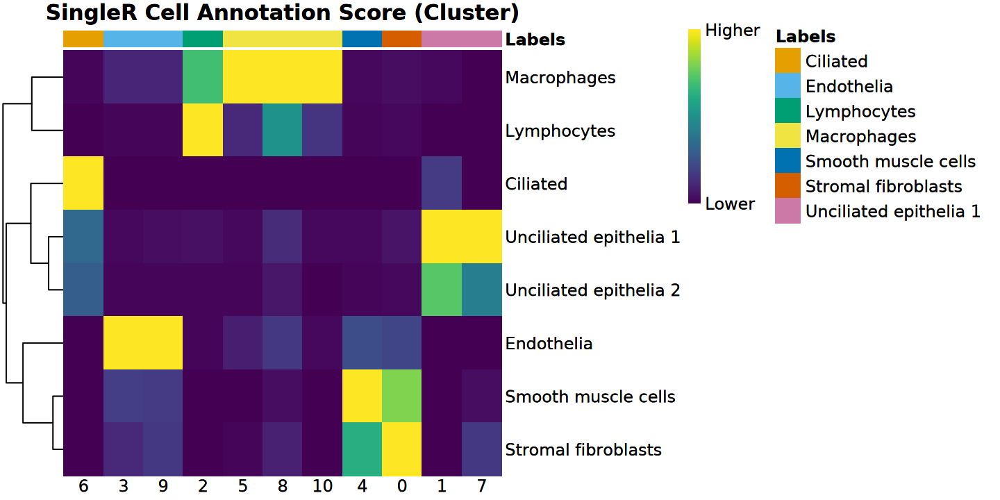

In [96]:
options(repr.plot.width = 12, repr.plot.height = 6)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [97]:
sc.inte$celltype.SingleR <- 
    celltype.SingleR$labels[sc.inte$seurat_clusters]

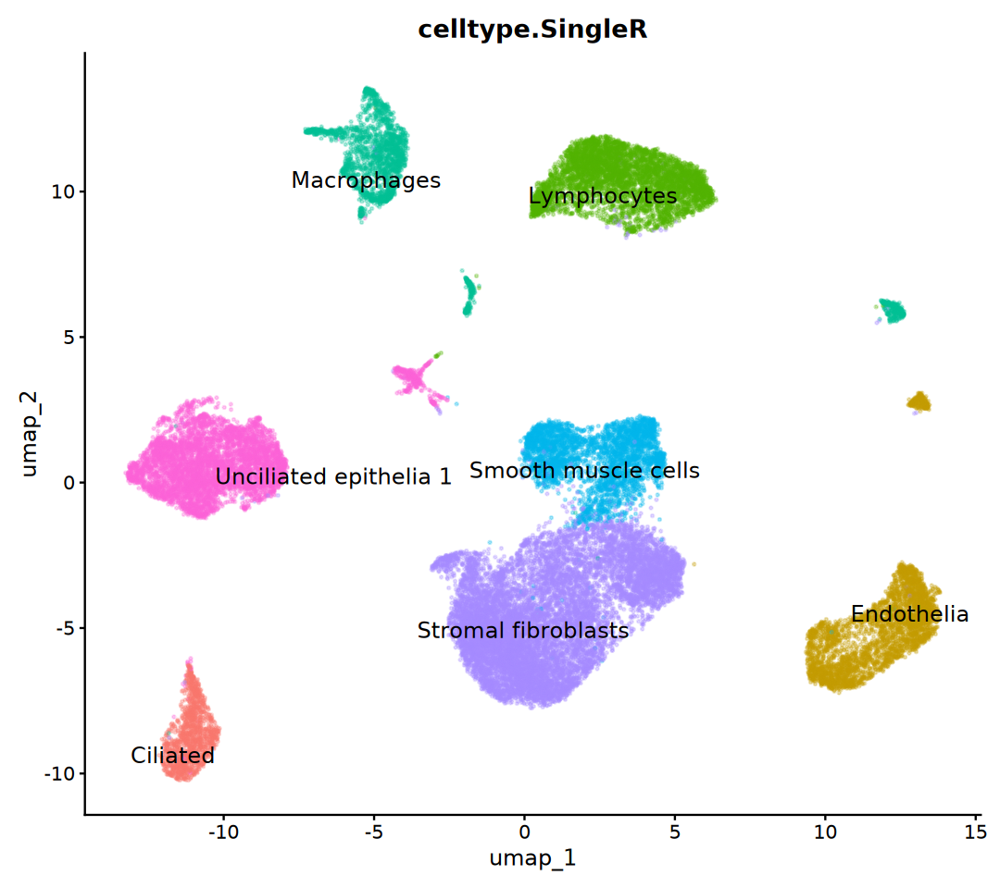

In [98]:
options(repr.plot.width = 9, repr.plot.height = 8)
DimPlot(sc.inte, reduction = "umap", group.by = "celltype.SingleR", 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3) + 
    NoLegend()

## b). Manual

In [99]:
gene_list <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC) |>
    summarise(genes = paste0('"', gene, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cluster, ": ", genes)) |> 
    pull(out)

In [100]:
gene_list |> cat(sep = "\n")

cluster_0: "SFRP4", "CLMP", "IGFBP6", "PTGDS", "ECM1", "PAPPA", "WNT2", "GFRA2", "RSPO3", "MMP10"
cluster_1: "PRSS8", "SFN", "UGT2B7", "S100A14", "DEFB1", "KLK11", "MMP7", "AC025580.1", "CBLC", "LINC01541"
cluster_2: "CD7", "CD3D", "CD2", "TRBC2", "CD96", "TRBC1", "CD3E", "KLRB1", "CD8A", "SLA2"
cluster_3: "ADGRL4", "CLDN5", "PLVAP", "SELE", "CLEC14A", "BCL6B", "CYYR1", "F2RL3", "ACKR1", "ESM1"
cluster_4: "RGS5", "CPE", "MYL9", "ADIRF", "NDUFA4L2", "EDNRB", "SLIT3", "NOTCH3", "MAP3K7CL", "GJA4"
cluster_5: "C1QA", "C1QB", "C1QC", "LILRB4", "MS4A7", "CD86", "SDS", "LILRB2", "MS4A4A", "MIR3945HG"
cluster_6: "C20orf85", "SNTN", "AL357093.2", "TMEM190", "WDR38", "STOML3", "GSTA3", "SRGAP3-AS2", "APOBEC4", "GAS2L2"
cluster_7: "UBE2C", "MKI67", "TOP2A", "PBK", "PKMYT1", "TROAP", "SPC25", "DLGAP5", "PIMREG", "EXO1"
cluster_8: "TPSAB1", "TPSB2", "CPA3", "HPGDS", "HDC", "MS4A2", "CALB2", "TRIM63", "GCSAML", "TPSG1"
cluster_9: "CCL21", "TBX1", "RELN", "SCN3A", "AC007998.3", "NFIA-AS2", "LINC01558

> - Cancer-associated fibroblasts cells (CAFs): "PDGFRA", "PDGFRB", "COL1A1", "COL3A1", "FN1"
> - Epithelial cells: "EPCAM", "KRT8", "KRT18", "PRSS8", "KLK11"
> - Ciliated epithelial cells: "SNTN", "STOML3", "GSTA3", "APOBEC4"
> - Endothelial cells: "PECAM1", "VWF", "CDH5", "CLDN5", "PLVAP"
> - Lymphatic endothelial cells: "PROX1", "PDPN", "LYVE1"
> - Smooth muscle cells: "RGS5", "MYH11", "NOTCH3", "EDNRB", "MYL9"
> - T cells: "CD3D", "CD3E", "CD2", "CD8A", "CD4"
> - B cells:
> - Plasma cells: "IGKC", "IGHA1", "JCHAIN", "MZB1"
> - Macrophages: "CD68", "CD14", "C1QA"
> - Mast cells: "TPSAB1", "TPSB2", "CPA3", "HDC", "KIT"
> - "CCL19", "CCL21"

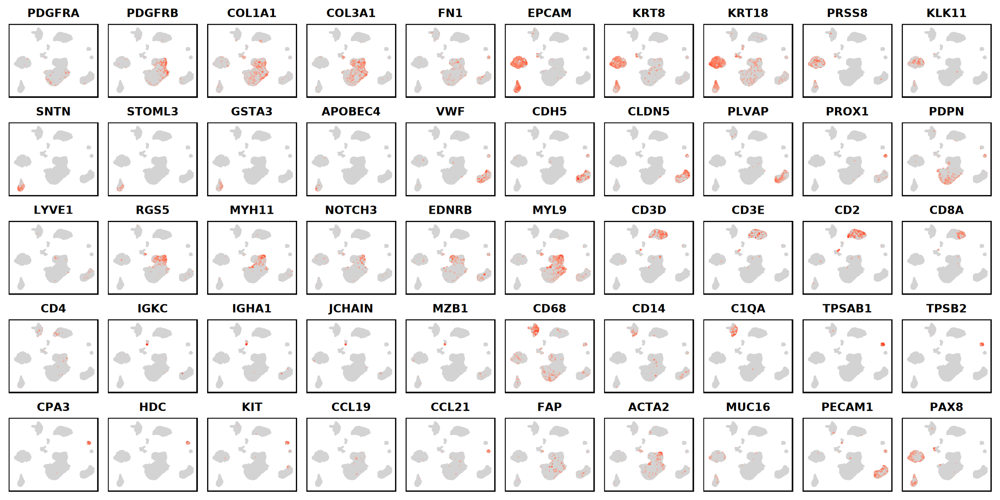

In [101]:
geneset <- c("PDGFRA", "PDGFRB", "COL1A1", "COL3A1", "FN1",
             "EPCAM", "KRT8", "KRT18", "PRSS8", "KLK11",
             "SNTN", "STOML3", "GSTA3", "APOBEC4",
             "VWF", "CDH5", "CLDN5", "PLVAP",
             "PROX1", "PDPN", "LYVE1",
             "RGS5", "MYH11", "NOTCH3", "EDNRB", "MYL9",
             "CD3D", "CD3E", "CD2", "CD8A", "CD4",
             "IGKC", "IGHA1", "JCHAIN", "MZB1",
             "CD68", "CD14", "C1QA",
             "TPSAB1", "TPSB2", "CPA3", "HDC", "KIT",
             "CCL19", "CCL21",
             "FAP", "ACTA2", "MUC16", "PECAM1", "PAX8")

options(repr.plot.width = 20, repr.plot.height = 10)
FeaturePlot(sc.inte, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 10) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(
        color = "black", linewidth = 1))

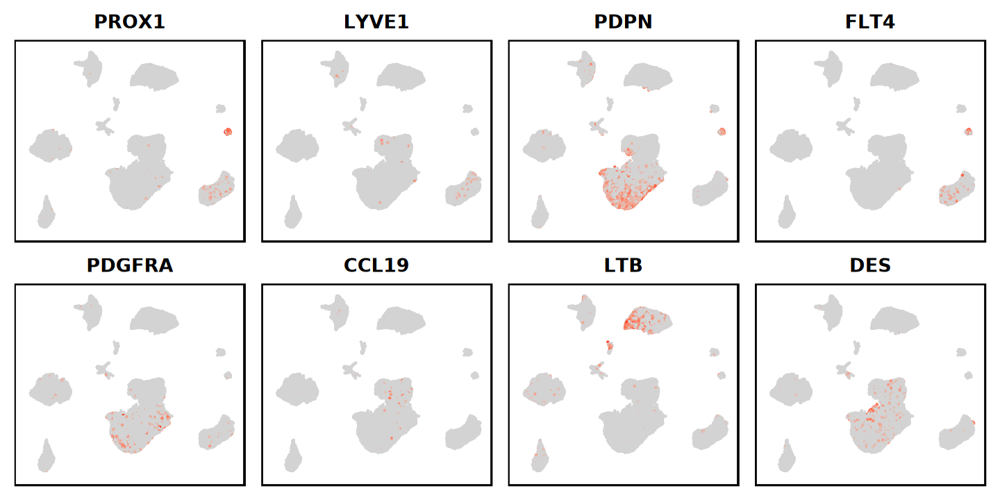

In [102]:
geneset <- c("PROX1", "LYVE1", "PDPN", "FLT4",
             "PDGFRA", "CCL19", "LTB", "DES")

options(repr.plot.width = 12, repr.plot.height = 6)
FeaturePlot(sc.inte, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 4) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(
        color = "black", linewidth = 1))

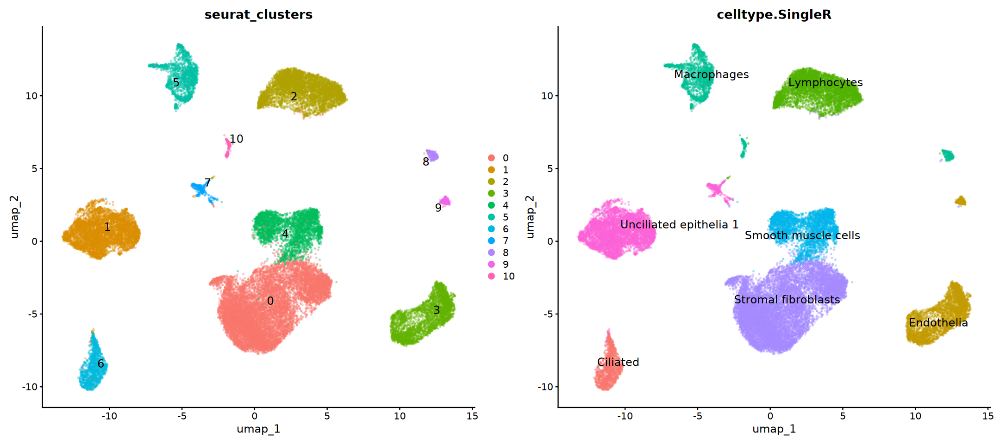

In [103]:
options(repr.plot.width = 18, repr.plot.height = 8)
DimPlot(sc.inte, reduction = "umap", 
        group.by = c("seurat_clusters", "celltype.SingleR"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3) + 
    NoLegend()

In [104]:
# Cell annotation with ChatGPT assistance
cluster2celltype <- c(
    "0" = "CAF", "1" = "Epithelial", "2" = "T",
    "3" = "Endothelial", "4" = "Smooth muscle", "5" = "Macrophages",
    "6" = "Ciliated epithelial", "7" = "Proliferating", "8" = "Mast cells",
    "9" = "Lymphatic endothelial", "10" = "Plasma cells")

In [105]:
sc.inte@meta.data$celltype <- 
    cluster2celltype[as.character(sc.inte$seurat_clusters)]

sc.inte <- RenameIdents(sc.inte, cluster2celltype)

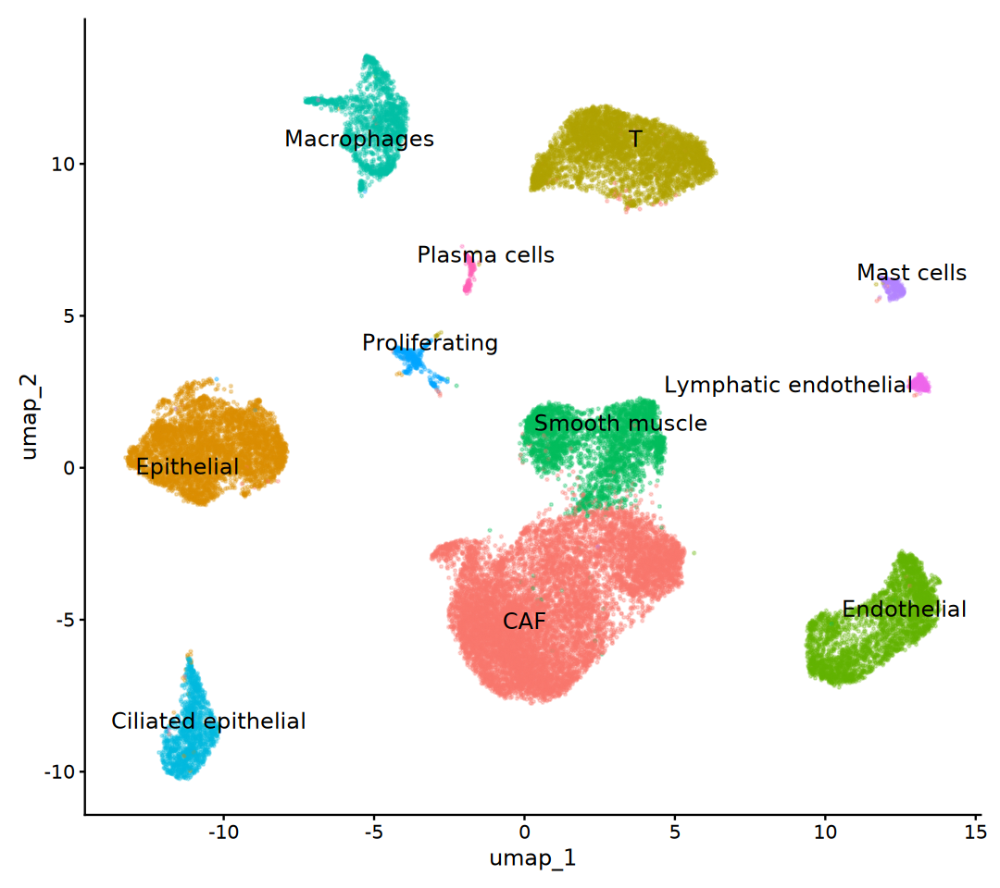

In [106]:
options(repr.plot.width = 9, repr.plot.height = 8)
DimPlot(sc.inte, reduction = "umap",
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3) + 
    NoLegend()

In [107]:
suppressPackageStartupMessages(library(SeuratDisk))

In [108]:
sc.inte

An object of class Seurat 
26147 features across 32269 samples within 1 assay 
Active assay: RNA (26147 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 5 dimensional reductions calculated: pca, cca, harmony, umap, tsne

In [111]:
output_dir <- file.path(
    data_dir, "result", "GSE173682_EndometrialCancer.h5Seurat")
SaveH5Seurat(sc.inte, filename = output_dir, verbose = FALSE)

Creating h5Seurat file for version 3.1.5.9900



In [112]:
# Convert(output_dir, dest = "h5ad", verbose = FALSE)